In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import yaml
import torch
from torch.utils.data import DataLoader
from PIL import Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'

from src.data.audit import (
    natural_sort_key,
    load_frame,
    frame_mse,
    extract_frame_index,
    discover_sequences,
    check_missing_frame_gaps,
    check_duplicate_frames,
    check_image_decode_health,
    check_frame_dimensions,
    create_temporal_strips,
    run_audit
)
from src.data.dataset import (
    verify_split_isolation,
    create_and_save_split_manifest,
    TemporalSequenceDataset,
    IMAGENET_MEAN,
    IMAGENET_STD
)
from src.data.sampling import (
    uniform_sample,
    first_n,
    last_n,
    sparse_sample,
    random_sample,
    get_sampler
)
from src.data.remote_ingestion import (
    is_ffmpeg_available,
    extract_frames_from_video
)
print('Modules imported successfully')

Modules imported successfully


In [2]:
with open('configs/experiment.yaml') as f:
    config = yaml.safe_load(f)

data_root = Path(config['dataset']['root'])
print('Config dataset:', config['dataset']['name'])
print('Data root:', str(data_root))
print('Max frames:', config['sequence']['max_frames'])
print('Frame size:', config['sequence']['frame_size'])

Config dataset: ssv2
Data root: data
Max frames: 8
Frame size: [224, 224]


In [3]:
sequences_by_class = discover_sequences(data_root)
total_sequences = sum(len(seqs) for seqs in sequences_by_class.values())
print('Total classes discovered:', len(sequences_by_class))
print('Total sequences discovered:', total_sequences)
for class_name in sorted(sequences_by_class.keys())[:5]:
    print(f'Class: {class_name} -> {len(sequences_by_class[class_name])} sequences')

Total classes discovered: 20
Total sequences discovered: 2000
Class: Closing something -> 100 sequences
Class: Covering something -> 100 sequences
Class: Moving something away from the camera -> 100 sequences
Class: Moving something towards the camera -> 100 sequences
Class: Opening something -> 100 sequences


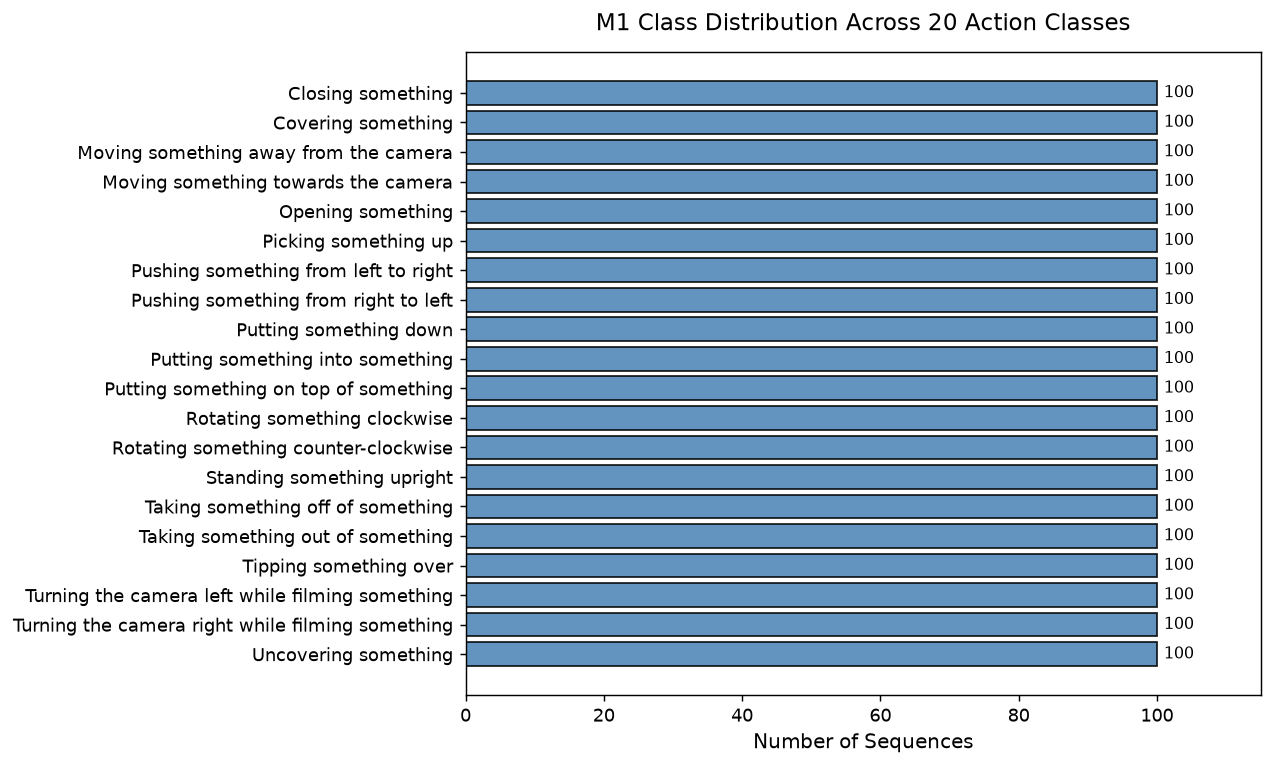

In [4]:
class_names = sorted(list(sequences_by_class.keys()))
class_counts = [len(sequences_by_class[c]) for c in class_names]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(class_names, class_counts, color='steelblue', edgecolor='black', alpha=0.85)
ax.set_xlabel('Number of Sequences', fontsize=11)
ax.set_title('M1 Class Distribution Across 20 Action Classes', fontsize=13, pad=12)
ax.set_xlim(0, max(class_counts) * 1.15)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height() / 2, f'{int(w)}', va='center', fontsize=9)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [5]:
sample_seq = sequences_by_class[list(sequences_by_class.keys())[0]][0]
sample_frame_indices = [extract_frame_index(f.name) for f in sample_seq['frames']]
print('Sample frame indices:', sample_frame_indices)
print('Sample sequence gap count:', check_missing_frame_gaps(sample_seq['frames']))

all_gaps = sum(check_missing_frame_gaps(s['frames']) for seqs in sequences_by_class.values() for s in seqs)
print('Total index gaps across dataset:', all_gaps)

sample_frames = sample_seq['frames']
f1 = load_frame(sample_frames[0])
f2 = load_frame(sample_frames[1])
mse_val = frame_mse(f1, f2)
print('Frame 0 shape:', f1.shape)
print('Frame 1 shape:', f2.shape)
print('Consecutive frame MSE:', mse_val)
print('Sample sequence duplicate frames:', check_duplicate_frames(sample_frames, mse_threshold=0.001))

Sample frame indices: [1, 2, 3, 4, 5, 6, 7, 8]
Sample sequence gap count: 0
Total index gaps across dataset: 0
Frame 0 shape: (224, 224, 3)
Frame 1 shape: (224, 224, 3)
Consecutive frame MSE: 0.001519779684749717
Sample sequence duplicate frames: 0


In [6]:
test_paths = [Path(f'frame_{i}.jpg') for i in [1, 10, 2, 20, 3]]
lexical_sorted = sorted(test_paths, key=lambda x: x.name)
natural_sorted = sorted(test_paths, key=natural_sort_key)
print('Lexical sort:', [p.name for p in lexical_sorted])
print('Natural sort:', [p.name for p in natural_sorted])
print('Natural sort indices:', [extract_frame_index(p.name) for p in natural_sorted])

Lexical sort: ['frame_1.jpg', 'frame_10.jpg', 'frame_2.jpg', 'frame_20.jpg', 'frame_3.jpg']
Natural sort: ['frame_1.jpg', 'frame_2.jpg', 'frame_3.jpg', 'frame_10.jpg', 'frame_20.jpg']
Natural sort indices: [1, 2, 3, 10, 20]


In [7]:
total_tested = 0
total_corrupt = 0
for class_name, seqs in sequences_by_class.items():
    tested, corrupt = check_image_decode_health(seqs[0]['frames'])
    total_tested += tested
    total_corrupt += corrupt

dim_info = check_frame_dimensions(sample_seq['frames'])
print('Total frames decode tested:', total_tested)
print('Corrupted frames detected:', total_corrupt)
print('Dimension consistency:', dim_info['consistent'])
print('Dimensions found:', dim_info['dimensions_found'])

Total frames decode tested: 160
Corrupted frames detected: 0
Dimension consistency: True
Dimensions found: [[224, 224]]


In [8]:
audit_results = run_audit(
    data_root=str(data_root),
    output_path='results/dataset_audit.json',
    strips_output='results/figures/audit_strips.png'
)
print('Global sequence count:', audit_results['global']['total_sequences'])
print('Global classes count:', audit_results['global']['total_classes'])
print('Global frames statistics:', audit_results['global']['frames_per_seq_global'])
print('Audit checks passed:', audit_results['checks'])

M1 DATASET AUDITOR — 7-CHECK INTEGRITY AUDIT

Discovered 20 classes in data:
  Closing something                      | seqs= 100 | frames=8.0±0.0
  Covering something                     | seqs= 100 | frames=8.0±0.0
  Moving something away from the camera  | seqs= 100 | frames=8.0±0.0
  Moving something towards the camera    | seqs= 100 | frames=8.0±0.0
  Opening something                      | seqs= 100 | frames=8.0±0.0
  Picking something up                   | seqs= 100 | frames=8.0±0.0
  Pushing something from left to right   | seqs= 100 | frames=8.0±0.0
  Pushing something from right to left   | seqs= 100 | frames=8.0±0.0
  Putting something down                 | seqs= 100 | frames=8.0±0.0
  Putting something into something       | seqs= 100 | frames=8.0±0.0
  Putting something on top of something  | seqs= 100 | frames=8.0±0.0
  Rotating something clockwise           | seqs= 100 | frames=8.0±0.0
  Rotating something counter-clockwise   | seqs= 100 | frames=8.0±0.0
  Standing so

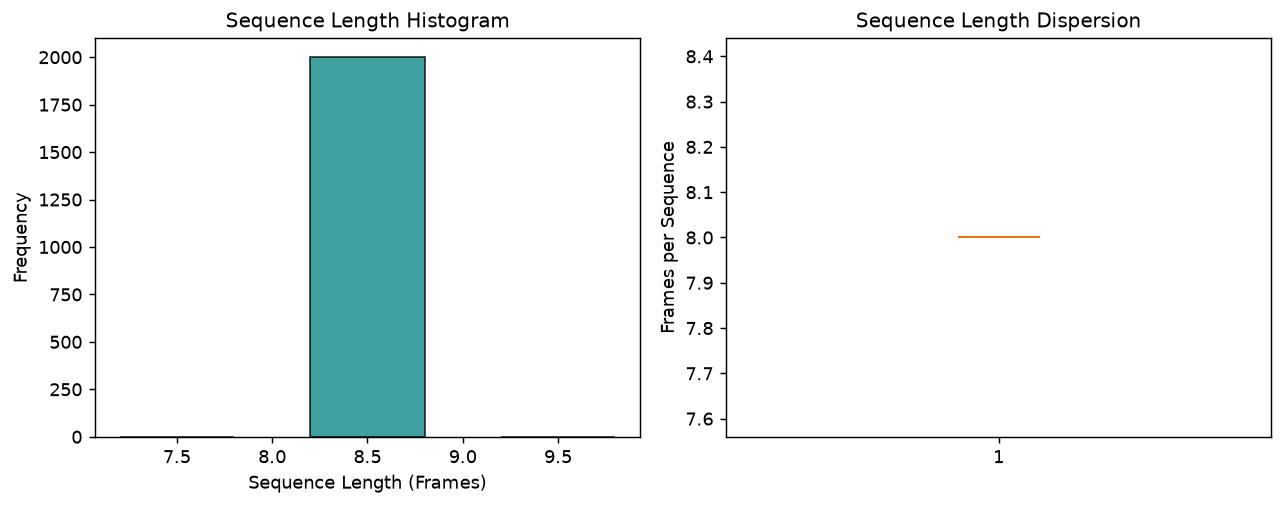

In [9]:
lengths = [s['n_frames'] for seqs in sequences_by_class.values() for s in seqs]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.hist(lengths, bins=range(min(lengths) - 1, max(lengths) + 3), color='teal', edgecolor='black', alpha=0.75, rwidth=0.6)
ax1.set_xlabel('Sequence Length (Frames)', fontsize=10)
ax1.set_ylabel('Frequency', fontsize=10)
ax1.set_title('Sequence Length Histogram', fontsize=11)

ax2.boxplot(lengths, vert=True, patch_artist=True, boxprops=dict(facecolor='powderblue'))
ax2.set_ylabel('Frames per Sequence', fontsize=10)
ax2.set_title('Sequence Length Dispersion', fontsize=11)
plt.tight_layout()
plt.show()

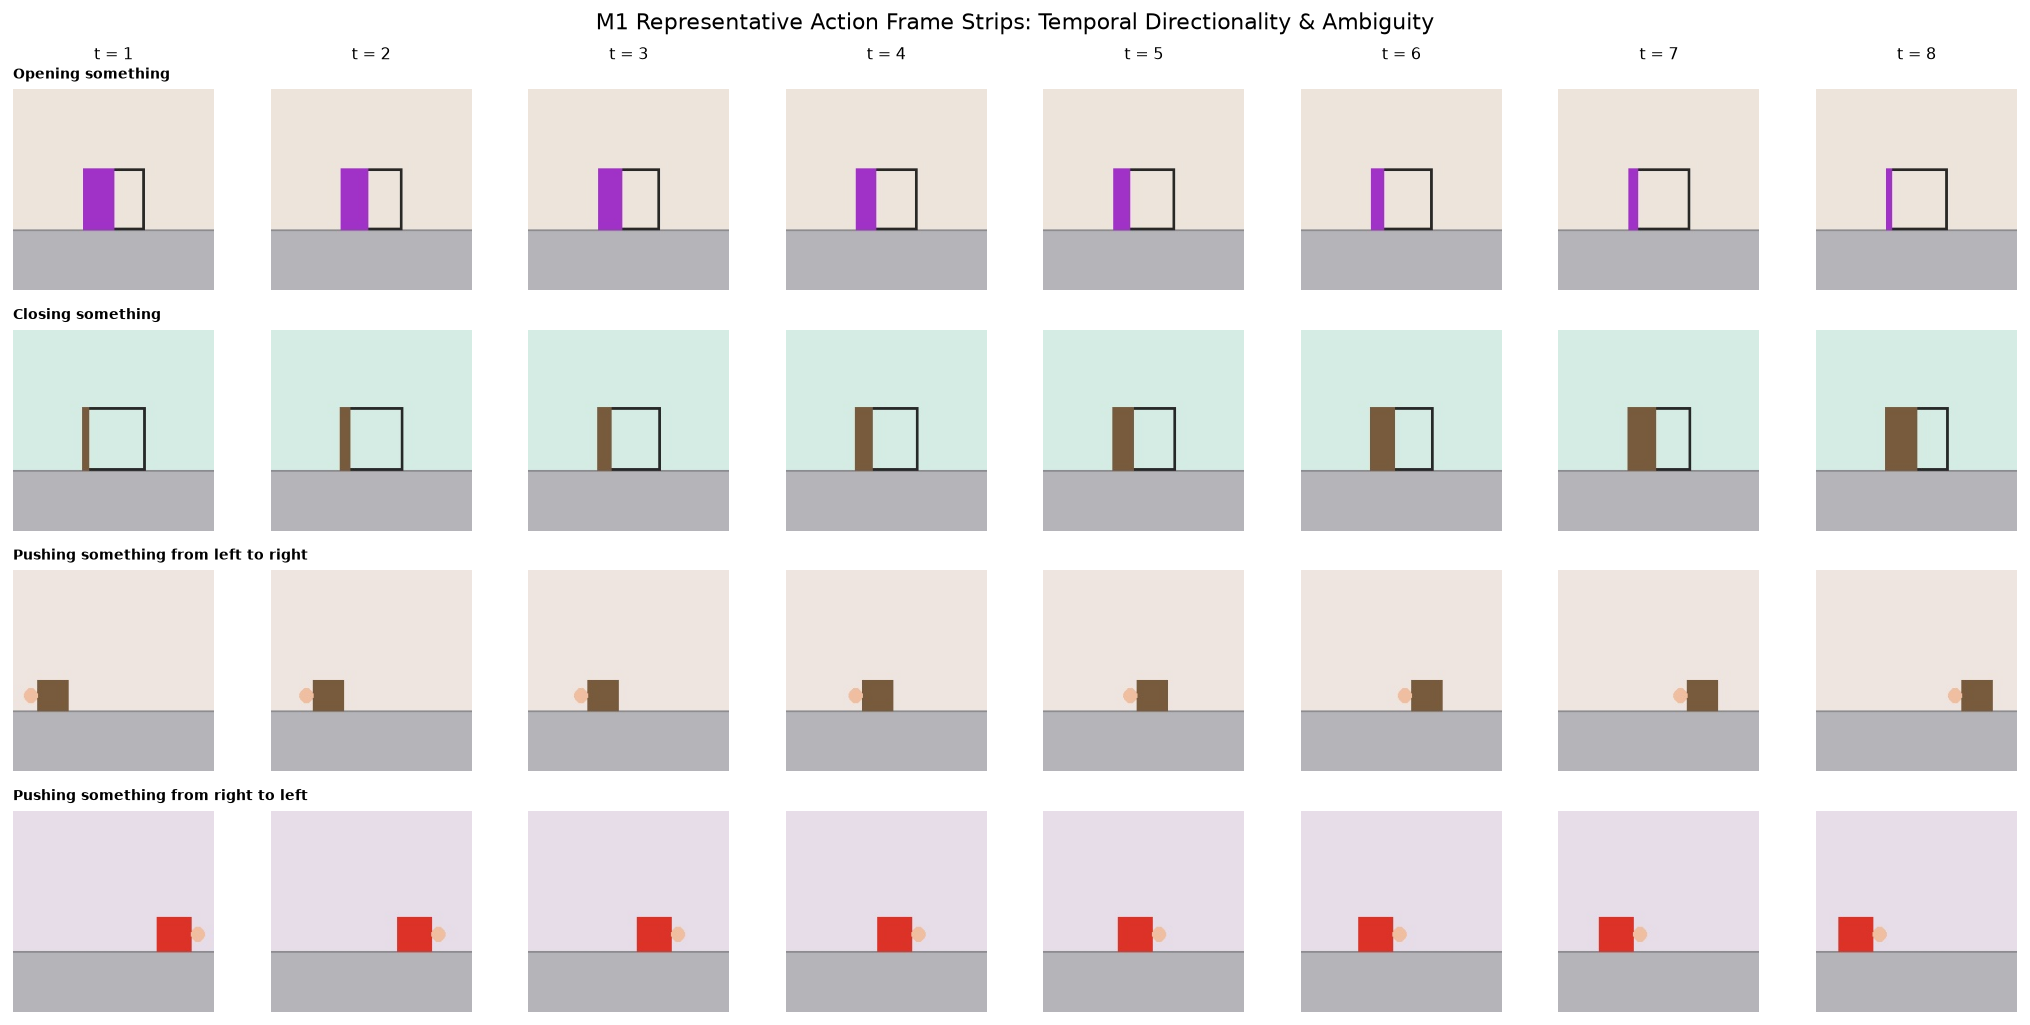

In [10]:
classes_to_display = [
    ('Opening something', 'Closing something'),
    ('Pushing something from left to right', 'Pushing something from right to left')
]

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
row_idx = 0
for pair in classes_to_display:
    for cls in pair:
        seq_frames = sequences_by_class[cls][0]['frames']
        for col_idx, f_path in enumerate(seq_frames):
            ax = axes[row_idx, col_idx]
            img = Image.open(f_path).convert('RGB')
            ax.imshow(img)
            ax.axis('off')
            if col_idx == 0:
                ax.set_title(cls, fontsize=8, loc='left', weight='bold')
            if row_idx == 0:
                ax.text(0.5, 1.15, f't = {col_idx + 1}', fontsize=9, ha='center', transform=ax.transAxes)
        row_idx += 1

plt.suptitle('M1 Representative Action Frame Strips: Temporal Directionality & Ambiguity', fontsize=12, y=0.98)
plt.tight_layout()
plt.show()

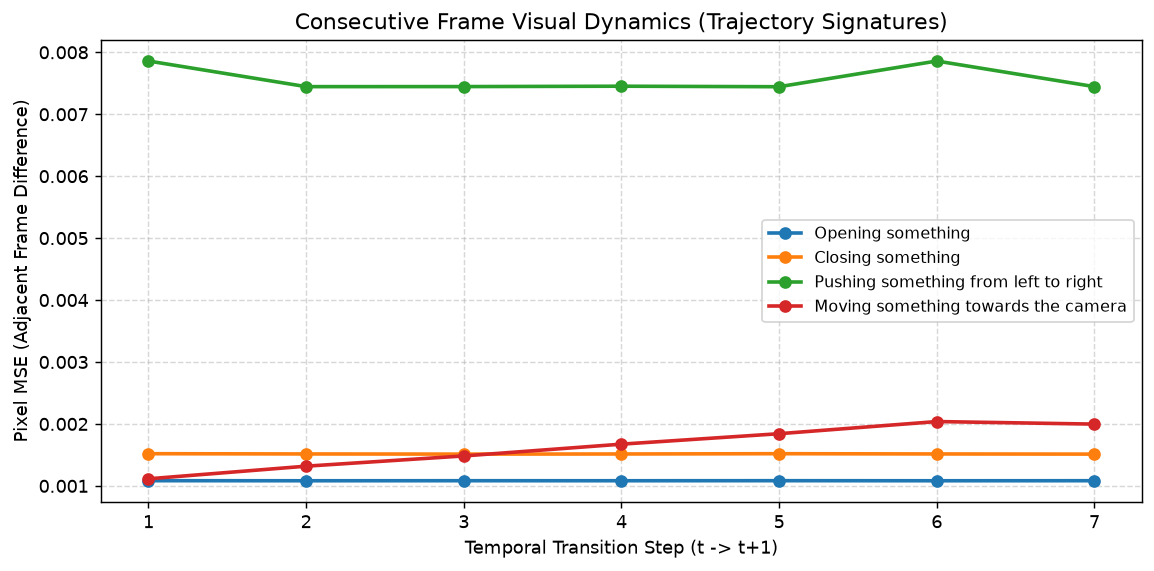

In [11]:
selected_actions = [
    'Opening something',
    'Closing something',
    'Pushing something from left to right',
    'Moving something towards the camera'
]

fig, ax = plt.subplots(figsize=(9, 4.5))
for cls in selected_actions:
    frames = sequences_by_class[cls][0]['frames']
    diffs = [frame_mse(load_frame(frames[i]), load_frame(frames[i + 1])) for i in range(len(frames) - 1)]
    ax.plot(range(1, len(diffs) + 1), diffs, marker='o', linewidth=2, label=cls)

ax.set_xlabel('Temporal Transition Step (t -> t+1)', fontsize=10)
ax.set_ylabel('Pixel MSE (Adjacent Frame Difference)', fontsize=10)
ax.set_title('Consecutive Frame Visual Dynamics (Trajectory Signatures)', fontsize=12)
ax.set_xticks(range(1, 8))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

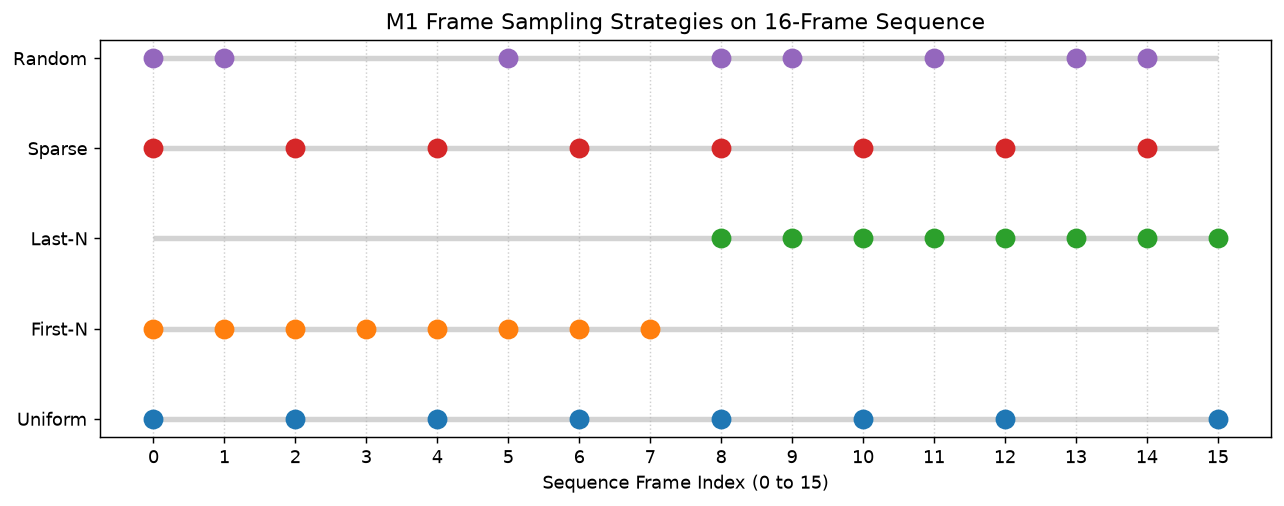

In [12]:
total_len = 16
target_t = 8
samplers = {
    'Uniform': [int(x) for x in uniform_sample(total_len, target_t)],
    'First-N': [int(x) for x in first_n(total_len, target_t)],
    'Last-N': [int(x) for x in last_n(total_len, target_t)],
    'Sparse': [int(x) for x in sparse_sample(total_len, target_t)],
    'Random': [int(x) for x in random_sample(total_len, target_t, seed=42)]
}

fig, ax = plt.subplots(figsize=(10, 4))
y_positions = list(range(len(samplers)))
for y, (name, indices) in zip(y_positions, samplers.items()):
    ax.hlines(y, 0, total_len - 1, color='lightgray', linewidth=3, zorder=1)
    ax.scatter(indices, [y] * len(indices), s=100, zorder=2, label=name)

ax.set_yticks(y_positions)
ax.set_yticklabels(list(samplers.keys()), fontsize=10)
ax.set_xlabel('Sequence Frame Index (0 to 15)', fontsize=10)
ax.set_title('M1 Frame Sampling Strategies on 16-Frame Sequence', fontsize=12)
ax.set_xticks(range(total_len))
ax.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [13]:
split_manifest = create_and_save_split_manifest(
    root=str(data_root),
    config=config,
    metadata_dir='data/metadata'
)
is_isolated = verify_split_isolation(split_manifest)
print('Zero leakage verified:', is_isolated)
print('Train sequence count:', split_manifest['counts']['train'])
print('Validation sequence count:', split_manifest['counts']['val'])
print('Test sequence count:', split_manifest['counts']['test'])
print('Total split sequences:', split_manifest['counts']['total'])

with open('data/metadata/sequences.csv') as f:
    csv_lines = f.readlines()
print('Sequences CSV total records:', len(csv_lines) - 1)
print('Sequences CSV sample row:', csv_lines[1].strip())

  [Leakage Guard] Saved split manifest → data/metadata/split_manifest.json (Zero frame overlap verified)
  [Leakage Guard] Saved sequence registry → data/metadata/sequences.csv
Zero leakage verified: True
Train sequence count: 1400
Validation sequence count: 300
Test sequence count: 300
Total split sequences: 2000
Sequences CSV total records: 2000
Sequences CSV sample row: vid_07_0000,Closing something,0,8,train


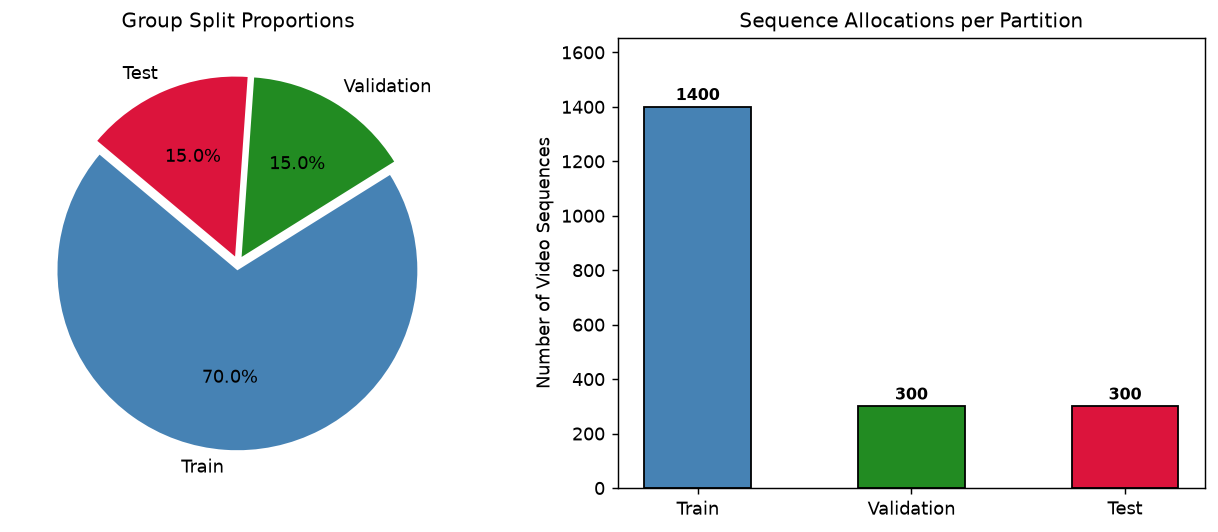

In [14]:
split_labels = ['Train', 'Validation', 'Test']
split_sizes = [
    split_manifest['counts']['train'],
    split_manifest['counts']['val'],
    split_manifest['counts']['test']
]
colors = ['steelblue', 'forestgreen', 'crimson']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ax1.pie(split_sizes, labels=split_labels, autopct='%1.1f%%', startangle=140, colors=colors, explode=(0.04, 0.04, 0.04))
ax1.set_title('Group Split Proportions', fontsize=11)

bars = ax2.bar(split_labels, split_sizes, color=colors, edgecolor='black', width=0.5)
ax2.set_ylabel('Number of Video Sequences', fontsize=10)
ax2.set_title('Sequence Allocations per Partition', fontsize=11)
ax2.set_ylim(0, max(split_sizes) * 1.18)
for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 25, f'{int(h)}', ha='center', fontsize=9, weight='bold')
plt.tight_layout()
plt.show()

Train dataset length: 1400
Val dataset length: 300
Test dataset length: 300
Batch tensor shape [B, T, C, H, W]: (4, 8, 3, 224, 224)
Batch labels shape [B]: (4,)
Batch labels: [5, 1, 9, 4]


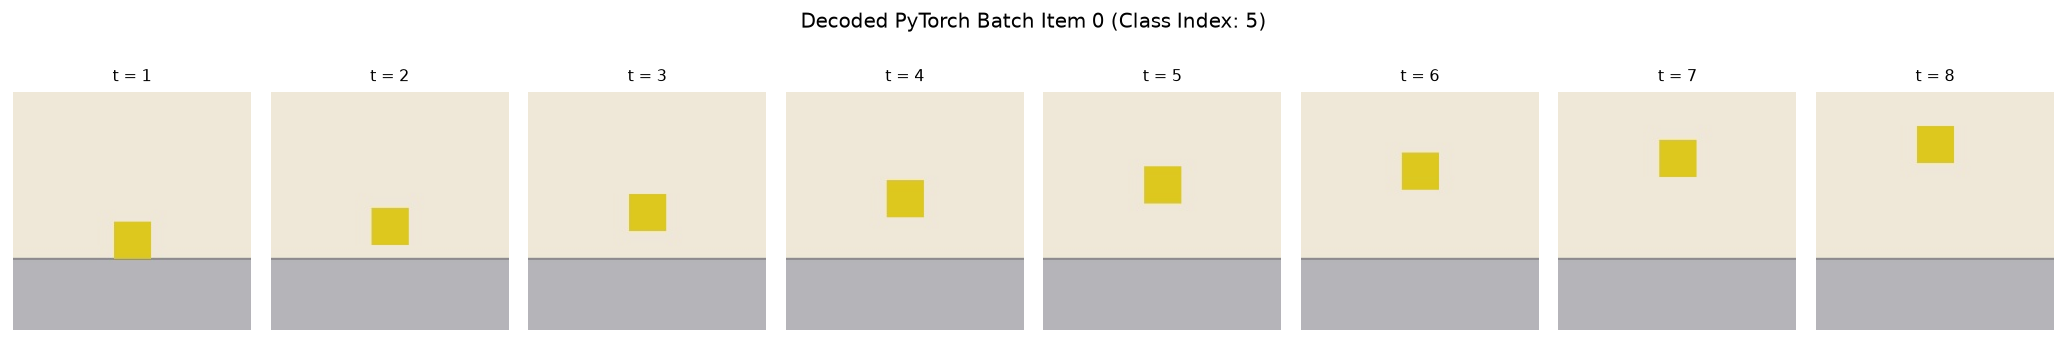

In [15]:
train_dataset = TemporalSequenceDataset(
    root=str(data_root),
    split='train',
    config=config,
    precomputed_splits=split_manifest
)
val_dataset = TemporalSequenceDataset(
    root=str(data_root),
    split='val',
    config=config,
    precomputed_splits=split_manifest
)
test_dataset = TemporalSequenceDataset(
    root=str(data_root),
    split='test',
    config=config,
    precomputed_splits=split_manifest
)

print('Train dataset length:', len(train_dataset))
print('Val dataset length:', len(val_dataset))
print('Test dataset length:', len(test_dataset))

loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
batch_x, batch_y = next(iter(loader))
print('Batch tensor shape [B, T, C, H, W]:', tuple(batch_x.shape))
print('Batch labels shape [B]:', tuple(batch_y.shape))
print('Batch labels:', batch_y.tolist())

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
sample_seq_tensor = batch_x[0]
for t in range(8):
    frame_tensor = sample_seq_tensor[t] * std + mean
    frame_tensor = torch.clamp(frame_tensor, 0.0, 1.0)
    frame_np = frame_tensor.permute(1, 2, 0).numpy()
    axes[t].imshow(frame_np)
    axes[t].axis('off')
    axes[t].set_title(f't = {t+1}', fontsize=9)
plt.suptitle(f'Decoded PyTorch Batch Item 0 (Class Index: {batch_y[0].item()})', fontsize=11, y=1.05)
plt.tight_layout()
plt.show()

In [16]:
ffmpeg_ok = is_ffmpeg_available()
print('FFmpeg available in system:', ffmpeg_ok)
test_video_frames = list(sequences_by_class[list(sequences_by_class.keys())[0]][0]['frames'])
print('Direct frame extraction input count:', len(test_video_frames))
print('Frame file sample:', test_video_frames[0].name)
print('Frame file exists:', test_video_frames[0].exists())

FFmpeg available in system: True
Direct frame extraction input count: 8
Frame file sample: frame_0001.jpg
Frame file exists: True
